> **日本語版について**: このノートブックは、[jpmorganchase/python-training](https://github.com/jpmorganchase/python-training) の日本語版です（Apache License 2.0）。原文の翻訳を基礎に、日本語版独自の補足・追加・修正を含む場合があり、独自の部分にはその旨を明記しています。
>
> この章には日本語版独自の修正があります。原文が使う API は終了しているため、原文のコードセルは実行できない記録として残し（実行対象外に設定）、代替の API で動くセルを追加しています。

# Web API からのデータ取得

「Web 2.0」で大きく変わったのは、外部向け API の整備です。開発者は、公開されたデータの上にツールを組み立てられるようになりました。

API の応答は、機械が読みやすい形式で返ってきます。接続の方式も決まっているため、安定してデータを取得できます。

API は数多く公開されています。利用に開発者キーの登録が必要なものもあります。たとえば [セントルイス連邦準備銀行の API](https://research.stlouisfed.org/docs/api/) です。無料で使えるものもあります。たとえば [Coindesk の API](https://www.coindesk.com/api) です。API を探すときは、[ProgrammableWeb のディレクトリ](https://www.programmableweb.com/apis/directory) が役立ちます。

## 大いなる力には、大いなる責任が伴います

プログラムから Web サイトにアクセスするときも、マナーを守って使いましょう。

ここでは、Coindesk の API でビットコインの日次価格を取得します。Coindesk の API は、他の多くの API と同じく、JSON（JavaScript Object Notation）形式でデータを返します。JSON は、そのまま DataFrame に変換できます。使うライブラリは `json` と `requests` です。

**注意（日本語版独自）**: このあとの原文のコードセルは、CoinDesk の API が終了しているため実行できません。原文の記録として残し、実行対象外（raw セル）に設定してあります。実際に動く取得の流れは、その直後の「修正（日本語版独自）」のセルで代替の API を使ってたどれます。

**修正（日本語版独自）: この API は終了しています**

原文が使う CoinDesk の Bitcoin Price Index API は、提供が終了しました。ドメイン自体が応答しないため、上のセルは現在は実行できません（2026年11月に確認）。原文のセルは記録として残します。

代わりに、キーなしで使えて、同じ流れ（JSON を取得し、DataFrame にして描く）をたどれる例として、為替レートの Frankfurter API を使います。題材はビットコイン価格からドル円レートに変わりますが、この章の要点は JSON の扱い方なので、読み替えで対応できます。

In [1]:
import requests

frankfurter_url = "https://api.frankfurter.dev/v1/2019-01-01..2019-01-31?base=USD&symbols=JPY"
result_fx = requests.get(frankfurter_url, timeout=15)
result_fx.raise_for_status()
result_fx

<Response [200]>

In [2]:
import json
import pandas as pd

jsondata_fx = json.loads(result_fx.content)
jsondata_fx["rates"]

{'2018-12-31': {'JPY': 109.91},
 '2019-01-02': {'JPY': 109.05},
 '2019-01-03': {'JPY': 107.69},
 '2019-01-04': {'JPY': 108.04},
 '2019-01-07': {'JPY': 108.26},
 '2019-01-08': {'JPY': 108.79},
 '2019-01-09': {'JPY': 108.86},
 '2019-01-10': {'JPY': 108.11},
 '2019-01-11': {'JPY': 108.31},
 '2019-01-14': {'JPY': 108.08},
 '2019-01-15': {'JPY': 108.56},
 '2019-01-16': {'JPY': 108.8},
 '2019-01-17': {'JPY': 108.77},
 '2019-01-18': {'JPY': 109.44},
 '2019-01-21': {'JPY': 109.66},
 '2019-01-22': {'JPY': 109.43},
 '2019-01-23': {'JPY': 109.7},
 '2019-01-24': {'JPY': 109.72},
 '2019-01-25': {'JPY': 109.92},
 '2019-01-28': {'JPY': 109.42},
 '2019-01-29': {'JPY': 109.46},
 '2019-01-30': {'JPY': 109.44},
 '2019-01-31': {'JPY': 108.64}}

In [3]:
data_fx = pd.DataFrame({"USD/JPY": {d: v["JPY"] for d, v in jsondata_fx["rates"].items()}})
data_fx.index = pd.to_datetime(data_fx.index)
data_fx

,USD/JPY
2018-12-31,109.91
2019-01-02,109.05
2019-01-03,107.69
2019-01-04,108.04
2019-01-07,108.26
2019-01-08,108.79
2019-01-09,108.86
2019-01-10,108.11
2019-01-11,108.31
2019-01-14,108.08


<Axes: >

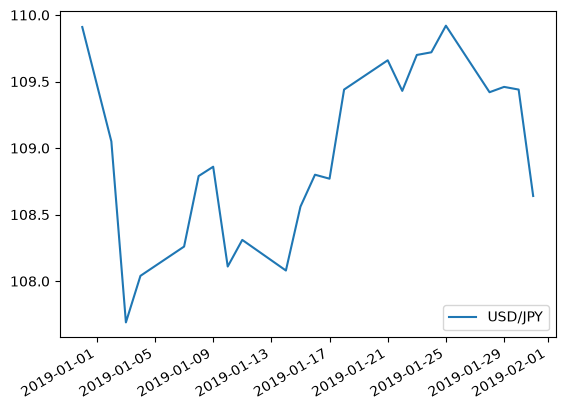

In [4]:
%matplotlib inline
data_fx.plot()

もう少し詳しく見てみましょう。データ取得で押さえるポイントはいくつかあります。

API ごとに、返ってくるデータの構造は違います。まずブラウザで URL を開いてみると、返ってくる内容がそのまま確認できることが多いです。試してみましょう。

[https://api.coindesk.com/v1/bpi/historical/close.json?start=2019-01-01&end=2019-07-01](https://api.coindesk.com/v1/bpi/historical/close.json?start=2019-01-01&end=2019-07-01)


この URL では、次の結果が返ってきます。
```
{
    "bpi":
    {
        "2019-01-01":3869.47,
        "2019-01-02":3941.2167,
        ...
    },
    "disclaimer": "This data was produced from the CoinDesk Bitcoin Price Index.",
    "time":
    {
        "updated":"Jul 2, 2019 00:03:00 UTC",
        "updatedISO":"2019-07-02T00:03:00+00:00"
    }
}
```

`bpi`、`disclaimer`、`time` の3つが、参照できるデータです。ここで主に使うのは `bpi` です。

データの分け方は API ごとに違います。他の API の例は、後で出てきます。

Python で JSON の中身を見てみます。

これを pandas の DataFrame に変換します。

pandas には `read_json` という関数もあります。ただし、JSON の構造によっては使いにくい場合があります。